In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import quote_plus
from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv()
engine = create_engine(
    f"mysql+pymysql://{os.getenv('MYSQL_USER')}:{quote_plus(os.getenv('MYSQL_PASSWORD'))}"
    f"@{os.getenv('MYSQL_HOST')}/{os.getenv('MYSQL_DB')}"
)

query = """
SELECT p.customerID, p.tenure, p.Contract, p.PaymentMethod, p.InternetService,
       p.SeniorCitizen, p.MonthlyCharges, p.churn_probability, p.risk_level,
       p.revenue_at_risk, c.TechSupport, c.OnlineSecurity, d.top_churn_drivers
FROM churn_predictions p
JOIN customers_clean c ON p.customerID = c.customerID
JOIN customer_churn_drivers d ON p.customerID = d.customerID
WHERE p.risk_level IN ('High', 'Medium')
"""
df = pd.read_sql(query, engine)
print(df.shape)
df["risk_level"].value_counts()

(3706, 13)


risk_level
High      2240
Medium    1466
Name: count, dtype: int64

In [8]:
RULES = [
    {
        "action": "Offer discounted annual plan",
        "offer": "15% off the monthly price for moving to a 1-year contract",
        "reason": "Month-to-month customer with high monthly charges",
        "test": lambda r: r.Contract == "Month-to-month" and r.MonthlyCharges >= 70,
    },
    {
        "action": "Contract upgrade incentive",
        "offer": "One free month or a device credit for moving to a 1-year contract",
        "reason": "Month-to-month customers can leave at any time",
        "test": lambda r: r.Contract == "Month-to-month",
    },
    {
        "action": "Free tech support trial",
        "offer": "3 months of free tech support",
        "reason": "Internet customer without tech support",
        "test": lambda r: r.InternetService != "No" and r.TechSupport == "No",
    },
    {
        "action": "Free online security trial",
        "offer": "3 months of free online security",
        "reason": "Internet customer without online security",
        "test": lambda r: r.InternetService != "No" and r.OnlineSecurity == "No",
    },
    {
        "action": "Move to auto-pay",
        "offer": "A 5 dollar bill credit for switching to automatic payment",
        "reason": "Pays by electronic check, which has high churn",
        "test": lambda r: r.PaymentMethod == "Electronic check",
    },
    {
        "action": "Fiber loyalty discount",
        "offer": "A loyalty discount on the fiber plan plus a speed check call",
        "reason": "High-paying fiber customer",
        "test": lambda r: r.InternetService == "Fiber optic" and r.MonthlyCharges >= 80,
    },
    {
        "action": "New customer check-in",
        "offer": "A welcome call and a setup help session in the first year",
        "reason": "Customer is in the first 12 months, when churn is highest",
        "test": lambda r: r.tenure <= 12,
    },
    {
        "action": "Senior support plan",
        "offer": "Priority phone support and a simplified bill",
        "reason": "Senior customer at risk of leaving",
        "test": lambda r: r.SeniorCitizen == 1,
    },
]

DEFAULT = {
    "action": "Loyalty reward",
    "offer": "A thank-you credit on the next bill",
    "reason": "At-risk customer with no specific trigger",
}

In [9]:
def recommend(row):
    matches = [rule for rule in RULES if rule["test"](row)]
    main = matches[0] if matches else DEFAULT
    second = matches[1] if len(matches) > 1 else None
    return pd.Series({
        "action": main["action"],
        "offer": main["offer"],
        "reason": main["reason"],
        "secondary_action": second["action"] if second else None,
    })

recs = df.apply(recommend, axis=1)
final = pd.concat([df, recs], axis=1)

final["action"].value_counts()

action
Offer discounted annual plan    2012
Contract upgrade incentive      1250
Free tech support trial          248
Free online security trial       123
Fiber loyalty discount            42
Move to auto-pay                  21
Loyalty reward                     7
Senior support plan                2
New customer check-in              1
Name: count, dtype: int64

In [10]:
final.sort_values("MonthlyCharges", ascending=False)[
    ["customerID", "Contract", "MonthlyCharges", "churn_probability",
     "top_churn_drivers", "action", "offer"]
].head(10)

,customerID,Contract,MonthlyCharges,churn_probability,top_churn_drivers,action,offer
2053,8199-ZLLSA,One year,118.35,0.6794,"avg_monthly_spend, StreamingMovies, Contract_T...",Fiber loyalty discount,A loyalty discount on the fiber plan plus a sp...
3514,2889-FPWRM,One year,117.80,0.4401,"avg_monthly_spend, Contract_Two year, Streamin...",Fiber loyalty discount,A loyalty discount on the fiber plan plus a sp...
3466,2302-ANTDP,Month-to-month,117.45,0.6306,"avg_monthly_spend, InternetService_Fiber optic...",Offer discounted annual plan,15% off the monthly price for moving to a 1-ye...
1709,4282-MSACW,One year,117.20,0.4618,"StreamingMovies, Contract_Two year, InternetSe...",Fiber loyalty discount,A loyalty discount on the fiber plan plus a sp...
3567,0186-CAERR,One year,116.30,0.3809,"Contract_Two year, StreamingMovies, InternetSe...",Fiber loyalty discount,A loyalty discount on the fiber plan plus a sp...
3037,9053-JZFKV,Two year,116.20,0.4681,"avg_monthly_spend, MonthlyCharges, tenure",Fiber loyalty discount,A loyalty discount on the fiber plan plus a sp...
1514,7923-IYJWY,Two year,116.10,0.3229,"avg_monthly_spend, tenure, InternetService_Fib...",Fiber loyalty discount,A loyalty discount on the fiber plan plus a sp...
1654,0052-DCKON,One year,115.80,0.4278,"MonthlyCharges, Contract_Two year, StreamingMo...",Fiber loyalty discount,A loyalty discount on the fiber plan plus a sp...
900,9659-QEQSY,Month-to-month,115.65,0.4853,"avg_monthly_spend, InternetService_Fiber optic...",Offer discounted annual plan,15% off the monthly price for moving to a 1-ye...
1861,1444-VVSGW,One year,115.65,0.6522,"avg_monthly_spend, Contract_Two year, MonthlyC...",Fiber loyalty discount,A loyalty discount on the fiber plan plus a sp...


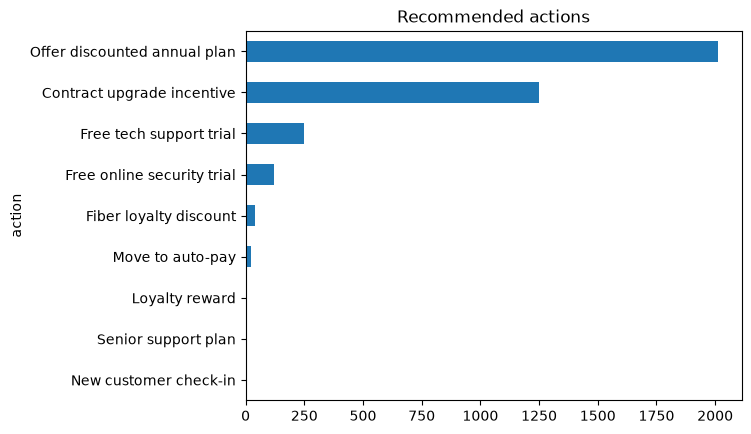

In [11]:
final["action"].value_counts().plot(kind="barh")
plt.title("Recommended actions")
plt.gca().invert_yaxis()
plt.show()

In [12]:
final.to_sql("retention_recommendations", engine, if_exists="replace", index=False)

3706